ALDANA: hace Ctrl+Shift+P → Developer: Reload Window. Sino no anda.

##### Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

## Dataset

In [2]:
# Lectura de dataset
df = pd.read_csv('weatherAUS_2026C2.csv')
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Descripcion

In [16]:
# Medidas del dataset (filas, columnas)
df.shape

(145412, 25)

In [17]:
# Medidas estadísticas principales del dataset
df.describe()

,Unnamed: 0,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
count,145412.000000,145412,143928.000000,144159.000000,142152.000000,82658.000000,75616.000000,135159.000000,143645.000000,142351.000000,142759.000000,140907.000000,130351.000000,130388.000000,89542.000000,86076.000000,143646.000000,141805.000000,142153.000000
mean,72728.184393,2013-04-04 08:55:50.149919,12.196528,23.223064,2.361516,5.468616,7.611241,40.036668,14.067277,18.661899,68.861521,51.532206,1017.647237,1015.255080,4.447287,4.509770,16.991981,21.683360,2.361242
min,0.000000,2007-11-01 00:00:00,-9.700000,-5.100000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,977.400000,0.000000,0.000000,-8.000000,-5.800000,0.000000
25%,36362.750000,2011-01-10 00:00:00,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,12.000000,57.000000,36.600000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000,0.000000
50%,72727.500000,2013-06-02 00:00:00,12.000000,22.600000,0.000000,4.800000,8.400000,38.000000,13.000000,18.000000,69.900000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000,0.000000
75%,109093.250000,2015-06-14 00:00:00,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.100000,65.700000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000,0.800000
max,145458.000000,2017-06-24 00:00:00,34.100000,49.100000,371.000000,145.000000,14.500000,135.000000,130.000000,86.000000,100.000000,100.000000,1041.200000,1039.800000,9.000000,9.000000,39.800000,47.000000,371.000000
std,41990.722236,NaN,6.417956,7.135927,8.479338,4.193871,3.785612,13.648259,8.936768,8.865457,19.062866,20.844414,7.113833,7.044507,2.887161,2.720306,6.509191,6.953072,8.479084


In [18]:
# Tipos de datos, valores no nulos, nulos y porcentaje de nulos.

# Como df.info() no muestra todas las columnas ya que sobrepasa el límite de filas, 
# se utiliza pd.option_context para mostrar todas las columnas y sus tipos de datos.

with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({
        'no_nulos': df.count(),
        'nulos': df.isna().sum(),
        'dtype': df.dtypes,
        '%_nulos': (df.isna().mean() * 100).round(2)}))

,no_nulos,nulos,dtype,%_nulos
Unnamed: 0,145412,0,int64,0.00
Date,145412,0,datetime64[us],0.00
Location,145412,0,str,0.00
MinTemp,143928,1484,float64,1.02
MaxTemp,144159,1253,float64,0.86
Rainfall,142152,3260,float64,2.24
Evaporation,82658,62754,float64,43.16
Sunshine,75616,69796,float64,48.00
WindGustDir,135096,10316,str,7.09
WindGustSpeed,135159,10253,float64,7.05


Notamos de este primer vistazo que las siguientes columnas tienen menos de un 5% faltante:
- Unnamed (correspondiente al índice)
- Date
- Location
- MinTemp
- MaxTemp
- Rainfall
- WindDir3pm
- WindSpeed9am
- WindSpeed3pm
- Humidity9am
- Humidity3pm
- Temp9am
- Temp3pm
- RainToday
- RainTomorrow
- RainfallTomorrow

Las siguientes columnas tienen un faltante de aproximadamente 10%:
- WindGustDir
- WindGustSpeed
- WindDir9am
- Pressure9am
- Pressure3pm

Y por ultimo estas variables poseen una falta de hasta un 50%:
- Evaporation
- Sunshine
- Cloud9am
- Cloud3pm

Hasta el momento sabemos que es un dataset que juntó datos diarios sobre el clima en Australia, y que busca predecir si al día siguiente lloverá o no. 
Para aprender mas al respecto, aplicaremos algunas funciones a las variables hasta dar con la información exacta que brinda cada columna:

In [19]:
### Date
# Para descubrir el primer día que se tomaron mediciones y el ultimo,
# convertimos la columna 'Date' a tipo datetime y luego usamos min() y max() para obtener las fechas.
df['Date'] = pd.to_datetime(df['Date'])
first_date = df['Date'].min()
last_date = df['Date'].max()

print(f"Primer día de mediciones: {first_date}")
print(f"Último día de mediciones: {last_date}")

Primer día de mediciones: 2007-11-01 00:00:00
Último día de mediciones: 2017-06-24 00:00:00


In [20]:
### Location
# Para hallar las locaciones, utilizamos unique().
locations = df['Location'].unique()

print(locations) # son 49

<StringArray>
[          'Albury',    'BadgerysCreek',            'Cobar',
     'CoffsHarbour',            'Moree',        'Newcastle',
        'NorahHead',    'NorfolkIsland',          'Penrith',
         'Richmond',           'Sydney',    'SydneyAirport',
       'WaggaWagga',      'Williamtown',       'Wollongong',
         'Canberra',      'Tuggeranong',      'MountGinini',
         'Ballarat',          'Bendigo',             'Sale',
 'MelbourneAirport',        'Melbourne',          'Mildura',
             'Nhil',         'Portland',         'Watsonia',
         'Dartmoor',         'Brisbane',           'Cairns',
        'GoldCoast',       'Townsville',         'Adelaide',
     'MountGambier',        'Nuriootpa',          'Woomera',
           'Albany',      'Witchcliffe',       'PearceRAAF',
     'PerthAirport',            'Perth',       'SalmonGums',
          'Walpole',           'Hobart',       'Launceston',
     'AliceSprings',           'Darwin',        'Katherine',
          

In [21]:
### WindGustDir
# Para hallar las locaciones, utilizamos unique().
WindGustDir = df['WindGustDir'].unique()

print(WindGustDir) # son 16 sin contar Nan.

# Las mismas entradas, correspondientes a cardinalidad, se repiten en la columna WindDir9am y WindDir3pm.

<StringArray>
[  'W', 'WNW', 'WSW',  'NE', 'NNW',   'N', 'NNE',  'SW',   nan, 'ENE', 'SSE',
   'S',  'NW',  'SE', 'ESE',   'E', 'SSW']
Length: 17, dtype: str


In [ ]:
### RainToday y RainTomorrow
# Sospechamos que son categoricas, por lo que procedemos a corroborarlo:
rain_today = df['RainToday'].unique()
rain_tomorrow = df['RainTomorrow'].unique()

print(rain_today)
print(rain_tomorrow) # Ambas son categoricas binarias, sin incluir el Nan.

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str


In [39]:
### Cloud9am y Cloud3pm
# Sospechamos que son categoricas, por lo que procedemos a corroborarlo:
cloud_9am = df['Cloud9am'].unique()
cloud_3pm = df['Cloud3pm'].unique()

print(cloud_9am)
print(cloud_3pm) # Ambas son categoricas (numericas pero discretas) del 0 al 9, sin incluir el Nan.   

# Para saber cuántas veces aparece cada valor en el dataset:
cloud_9am_count = df['Cloud9am'].value_counts()
cloud_3pm_count = df['Cloud3pm'].value_counts()

print(cloud_9am_count)
print("\n------------\n")
print(cloud_3pm_count)
# 9 aparece solo 3 veces sumando ambas.
# Según la Organización Meteorológica Mundial (OMM), significa Cielo obstruido / Invisible.

[ 8. nan  7.  1.  0.  5.  4.  2.  6.  3.  9.]
[nan  2.  8.  7.  1.  5.  4.  6.  3.  0.  9.]
Cloud9am
7.0    19965
1.0    15680
8.0    14690
0.0     8641
6.0     8168
2.0     6500
3.0     5912
5.0     5566
4.0     4418
9.0        2
Name: count, dtype: int64

------------

Cloud3pm
7.0    18226
1.0    14972
8.0    12650
6.0     8978
2.0     7224
3.0     6915
5.0     6815
4.0     5321
0.0     4974
9.0        1
Name: count, dtype: int64


En base a lo obtenido, podemos afirmar que el dataset contiene observaciones meteorológicas diarias de 49 estaciones de Australia, entre el 01/11/2007 y el 24/06/2017. Cada fila representa un día en una cierta ubicación, y reúne mediciones de temperatura, lluvia, viento, humedad, presión y nubosidad. El objetivo es predecir si lloverá al día siguiente (`RainTomorrow`).

| Variable | Significado | Unidad | Tipo | Rango observado |
|---|---|---|---|---|
| `Date` | Fecha de la observación | AAAA-MM-DD | Fecha (texto) | 2007-11-01 a 2017-06-24 |
| `Location` | Estación meteorológica | – | Categórica | 49 ubicaciones |
| `MinTemp` | Temperatura mínima del día | °C | Numérica continua | -9,7 a 34,1 |
| `MaxTemp` | Temperatura máxima del día | °C | Numérica continua | -5,1 a 49,1 |
| `Rainfall` | Lluvia caída en el día | mm | Numérica continua | 0 a 371 |
| `Evaporation` | Evaporación (tanque clase A) en las 24 h previas a las 9am | mm | Numérica continua | 0 a 145 |
| `Sunshine` | Horas de sol brillante en el día | horas | Numérica continua | 0 a 14,5 |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindGustSpeed` | Velocidad de la ráfaga más fuerte del día | km/h | Numérica continua | 6 a 135 |
| `WindDir9am` | Dirección del viento a las 9am | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindDir3pm` | Dirección del viento a las 3pm | Punto cardinal | Categórica (16 valores) | N, NNE, NE, ..., NNW |
| `WindSpeed9am` | Velocidad media del viento a las 9am | km/h | Numérica continua | 0 a 130 |
| `WindSpeed3pm` | Velocidad media del viento a las 3pm | km/h | Numérica continua | 0 a 86 |
| `Humidity9am` | Humedad relativa a las 9am | % | Numérica continua | 0 a 100 |
| `Humidity3pm` | Humedad relativa a las 3pm | % | Numérica continua | 0 a 100 |
| `Pressure9am` | Presión atmosférica a las 9am | hPa | Numérica continua | 980,3 a 1041,2 |
| `Pressure3pm` | Presión atmosférica a las 3pm | hPa | Numérica continua | 977,4 a 1039,8 |
| `Cloud9am` | Fracción del cielo cubierta por nubes a las 9am | Octas | Numérica discreta | 0 a 9 |
| `Cloud3pm` | Fracción del cielo cubierta por nubes a las 3pm | Octas | Numérica discreta | 0 a 9 |
| `Temp9am` | Temperatura a las 9am | °C | Numérica continua | -8,0 a 39,8 |
| `Temp3pm` | Temperatura a las 3pm | °C | Numérica continua | -5,8 a 47,0 |
| `RainToday` | Indica si llovió hoy (`Rainfall` > 1 mm) | Yes/No | Categórica binaria | Yes, No |
| `RainTomorrow` | Indica si lloverá mañana (**variable objetivo**) | Yes/No | Categórica binaria | Yes, No |
| `RainfallTomorrow` | Lluvia caída al día siguiente | mm | Numérica continua | 0 a 371 |

**Observaciones:**
- `RainToday` vale "Yes" cuando `Rainfall` > 1 mm
- `RainTomorrow` vale "Yes" cuando `RainfallTomorrow` > 1 mm.

- Por lo anterior, `RainfallTomorrow` contiene exactamente la información del target. No debe usarse como variable predictora, ya que provocaría *data leakage*.
- En `Cloud9am` y `Cloud3pm` la escala de octas va de 0 a 8; el valor 9 (presente solo en 2 registros de `Cloud9am`) indica cielo no visible.
- `Rainfall` (máx. 371 mm), `Evaporation` (máx. 145 mm) y `WindSpeed9am` (máx. 130 km/h) tienen valores máximos muy alejados del resto de la distribución, a revisar más adelante.

#### Gráficos descriptivos
##### Boxplots e Histogramas (variables numericas continuas)

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


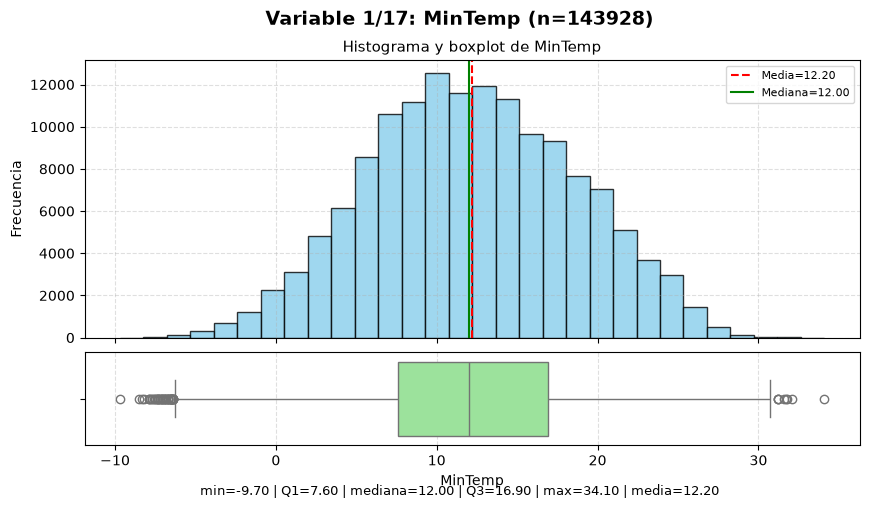

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


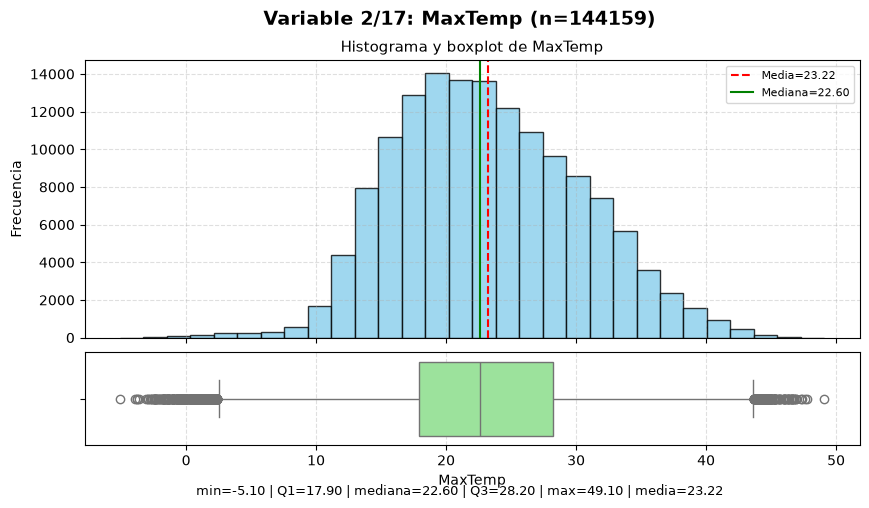

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


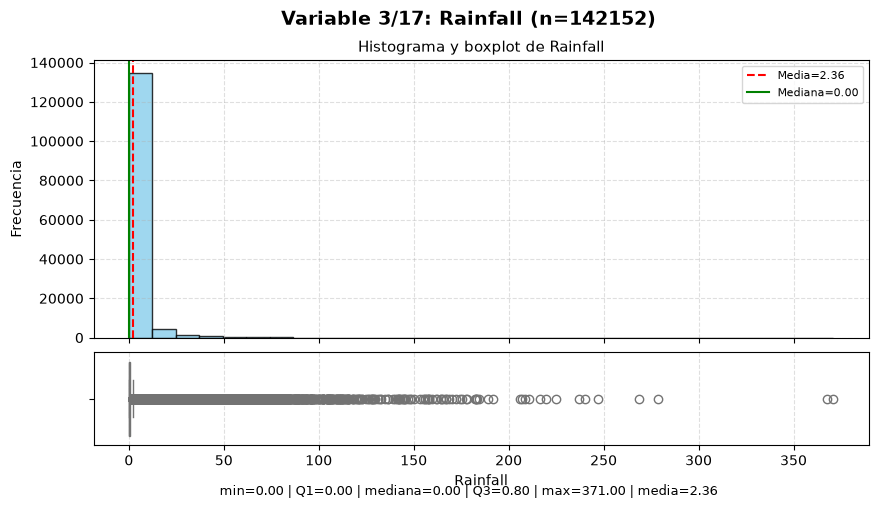

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


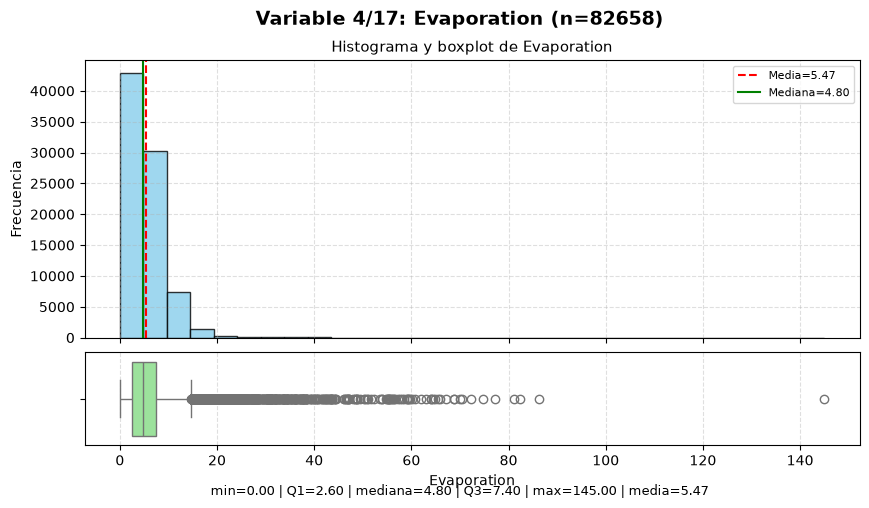

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


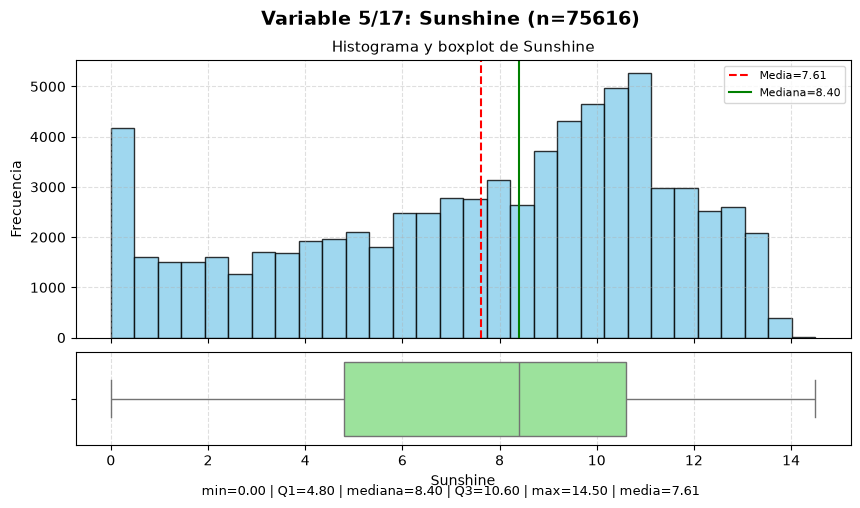

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


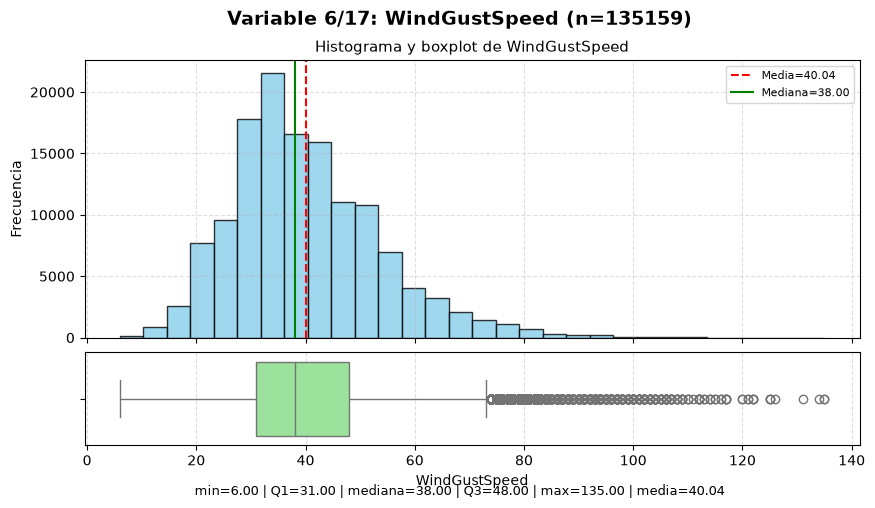

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


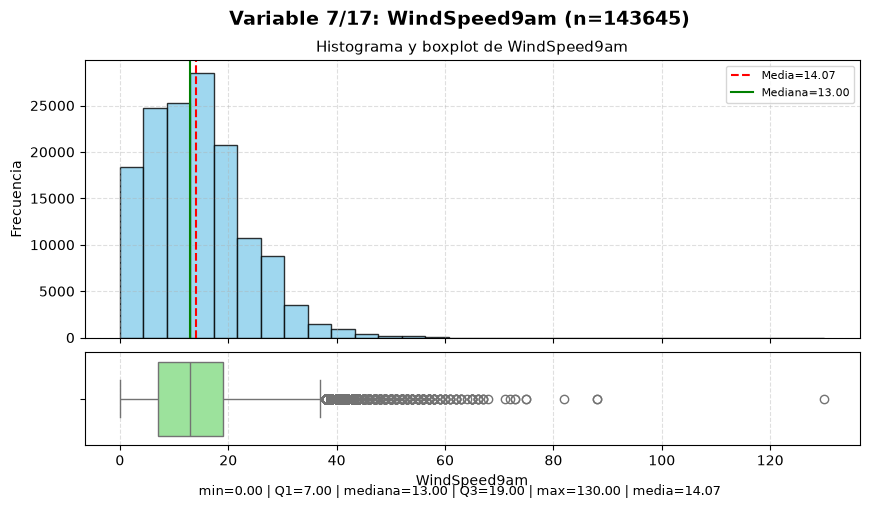

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


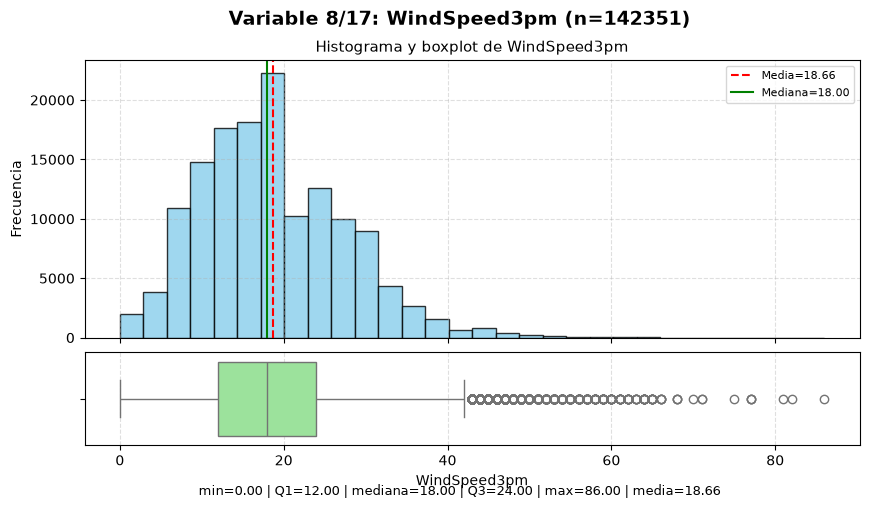

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


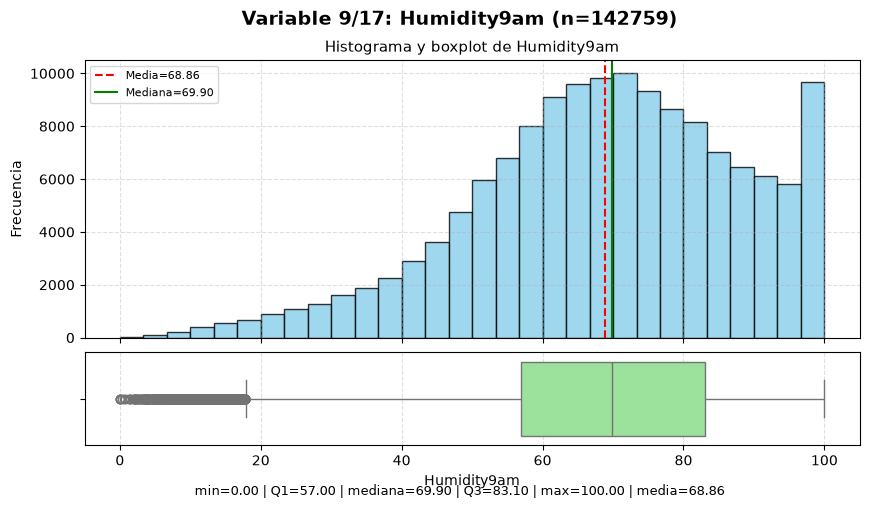

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


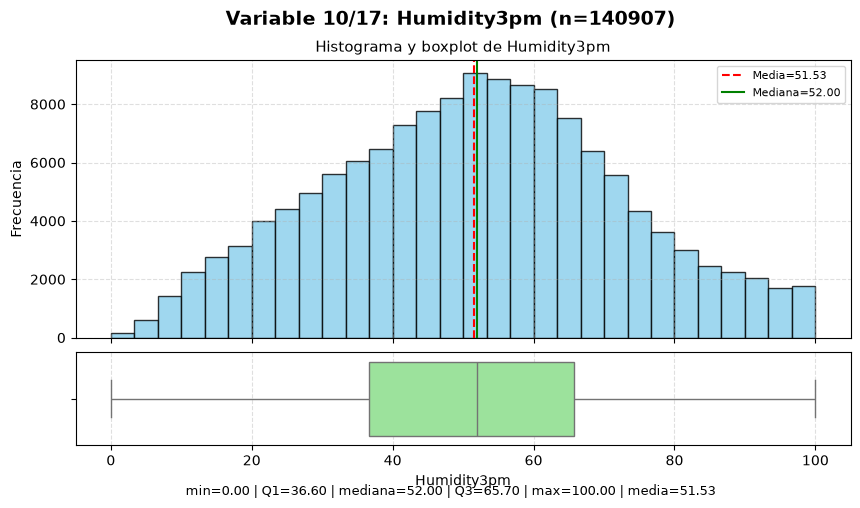

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


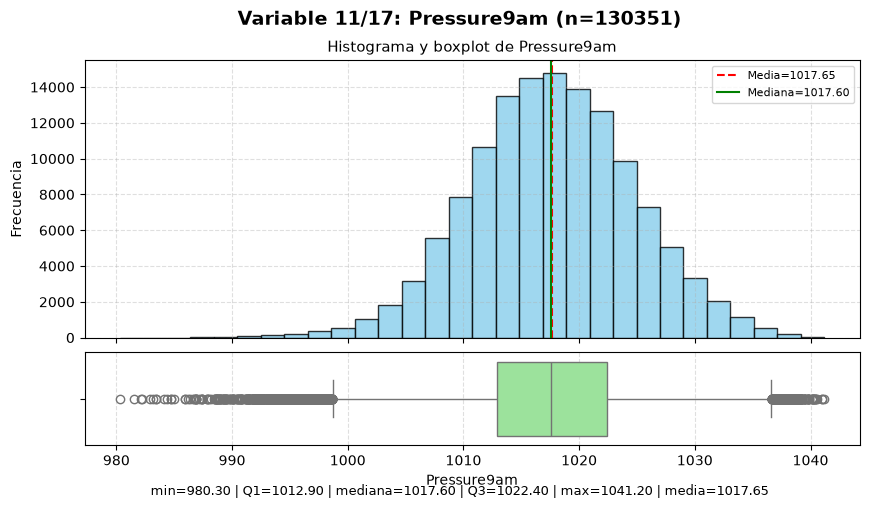

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


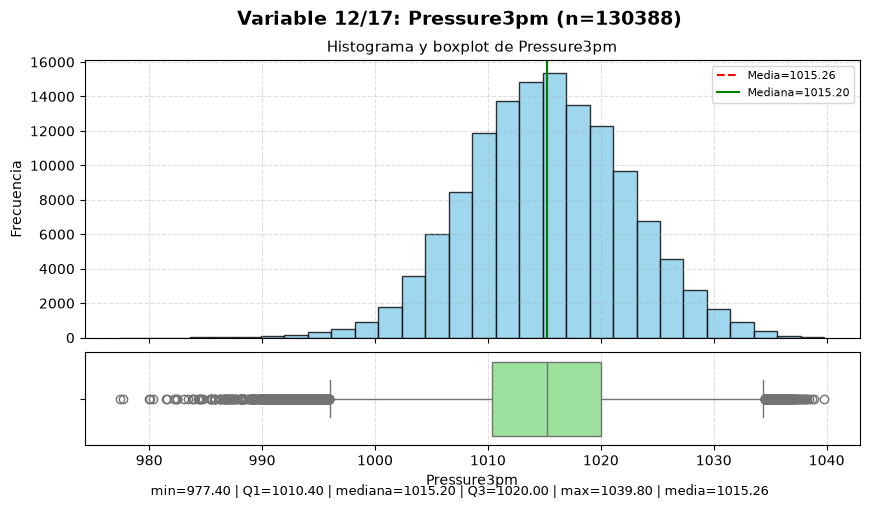

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


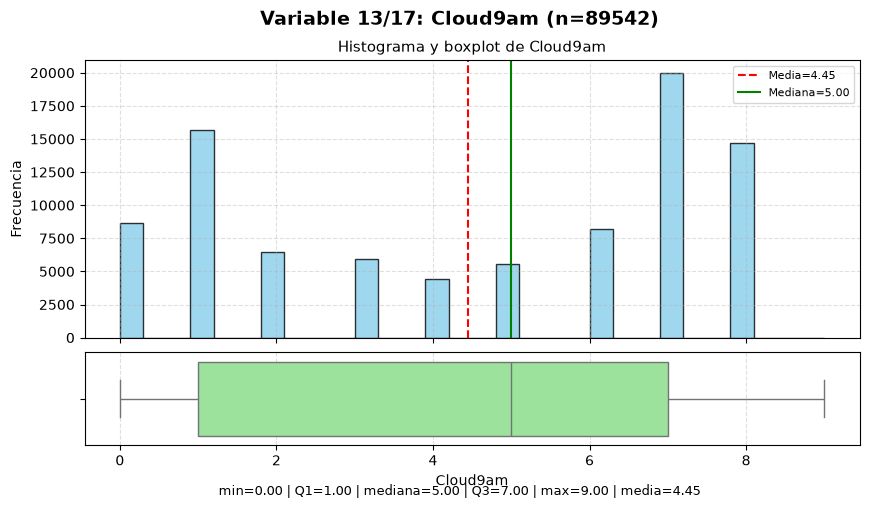

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


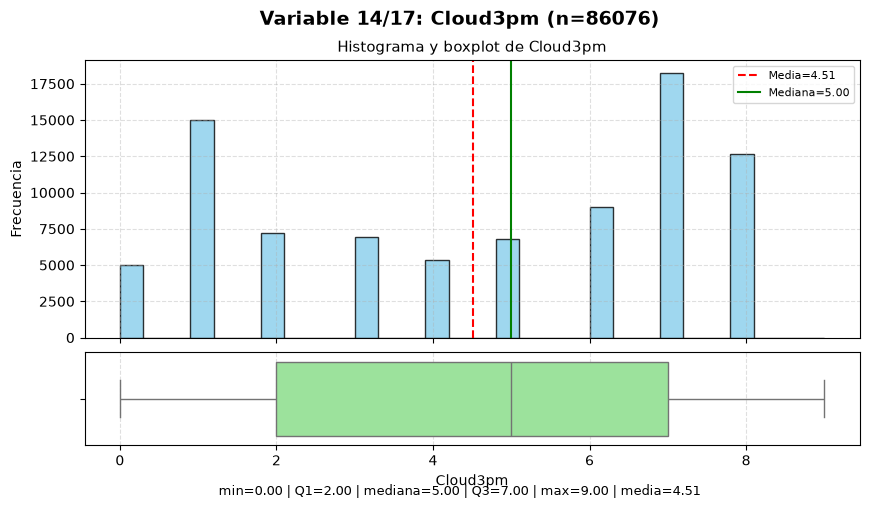

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


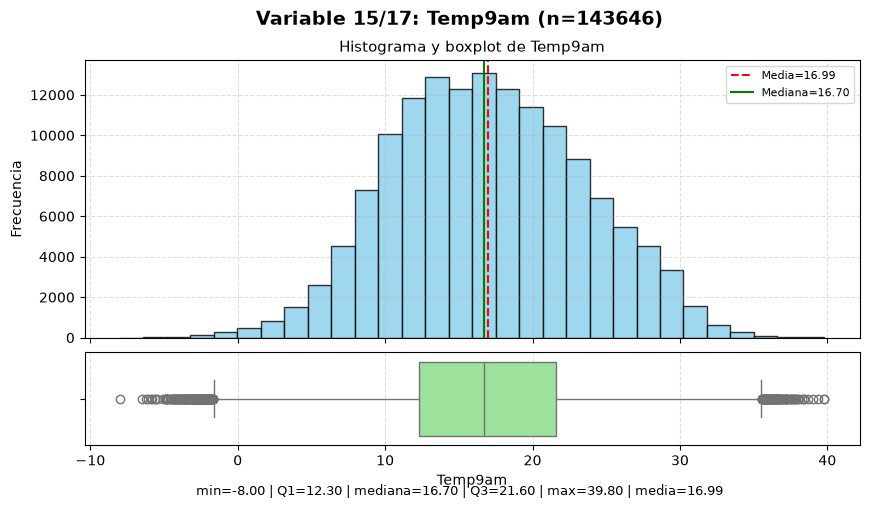

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


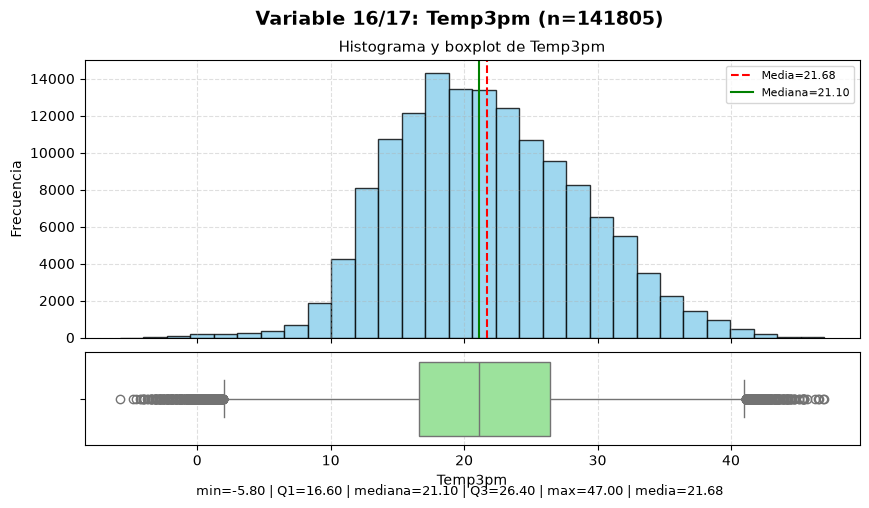

C:\Users\aldys\AppData\Local\Temp\ipykernel_5408\2976989096.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


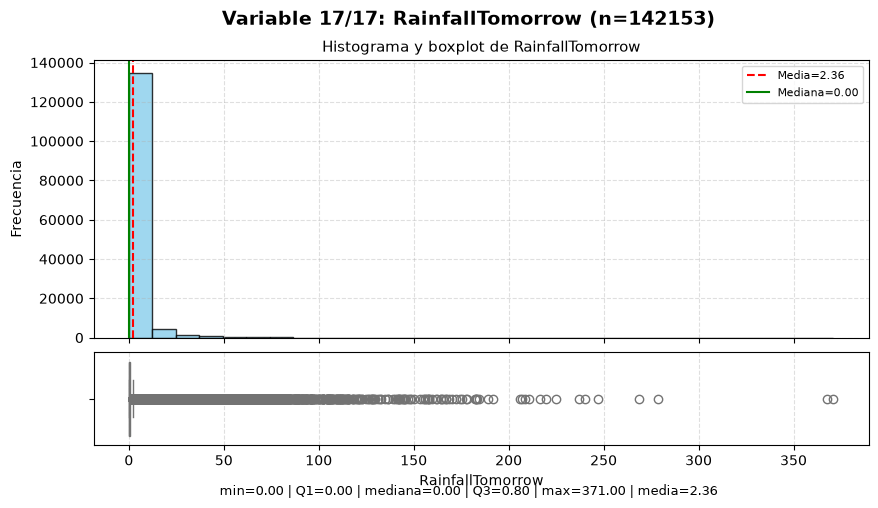

In [40]:
# Variables numéricas del dataset
variables_numericas = df.select_dtypes(include='number').columns.drop(['Unnamed: 0'])
# Descartamos del listado la columna 'Unnamed: 0' ya que es un índice y no aporta información relevante.

for i, col in enumerate(variables_numericas, start=1):
    datos = df[col].dropna()

    fig, (ax_hist, ax_box) = plt.subplots(
        2, 1, figsize=(10, 5), sharex=True,
        gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.08}
    )
    fig.suptitle(f'Variable {i}/{len(variables_numericas)}: {col} (n={len(datos)})',
                 fontsize=14, fontweight='bold')

    # Histograma
    ax_hist.hist(datos, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
    ax_hist.axvline(datos.mean(), color='red', linestyle='--', linewidth=1.5,
                    label=f'Media={datos.mean():.2f}')
    ax_hist.axvline(datos.median(), color='green', linestyle='-', linewidth=1.5,
                    label=f'Mediana={datos.median():.2f}')
    ax_hist.set_title(f'Histograma y boxplot de {col}', fontsize=11)
    ax_hist.set_ylabel('Frecuencia')
    ax_hist.grid(linestyle='--', alpha=0.4)
    ax_hist.legend(fontsize=8)

    # Boxplot
    sns.boxplot(x=datos, ax=ax_box, color='lightgreen')
    ax_box.set_xlabel(col)
    ax_box.grid(axis='x', linestyle='--', alpha=0.4)

    # Resumen numérico debajo de los gráficos
    resumen = (f'min={datos.min():.2f} | Q1={datos.quantile(0.25):.2f} | '
               f'mediana={datos.median():.2f} | Q3={datos.quantile(0.75):.2f} | '
               f'max={datos.max():.2f} | media={datos.mean():.2f}')
    fig.text(0.5, 0.01, resumen, ha='center', fontsize=9)

    plt.tight_layout(rect=[0, 0.04, 1, 0.94])
    plt.show()


##### Grafico de barras (variables categóricas)

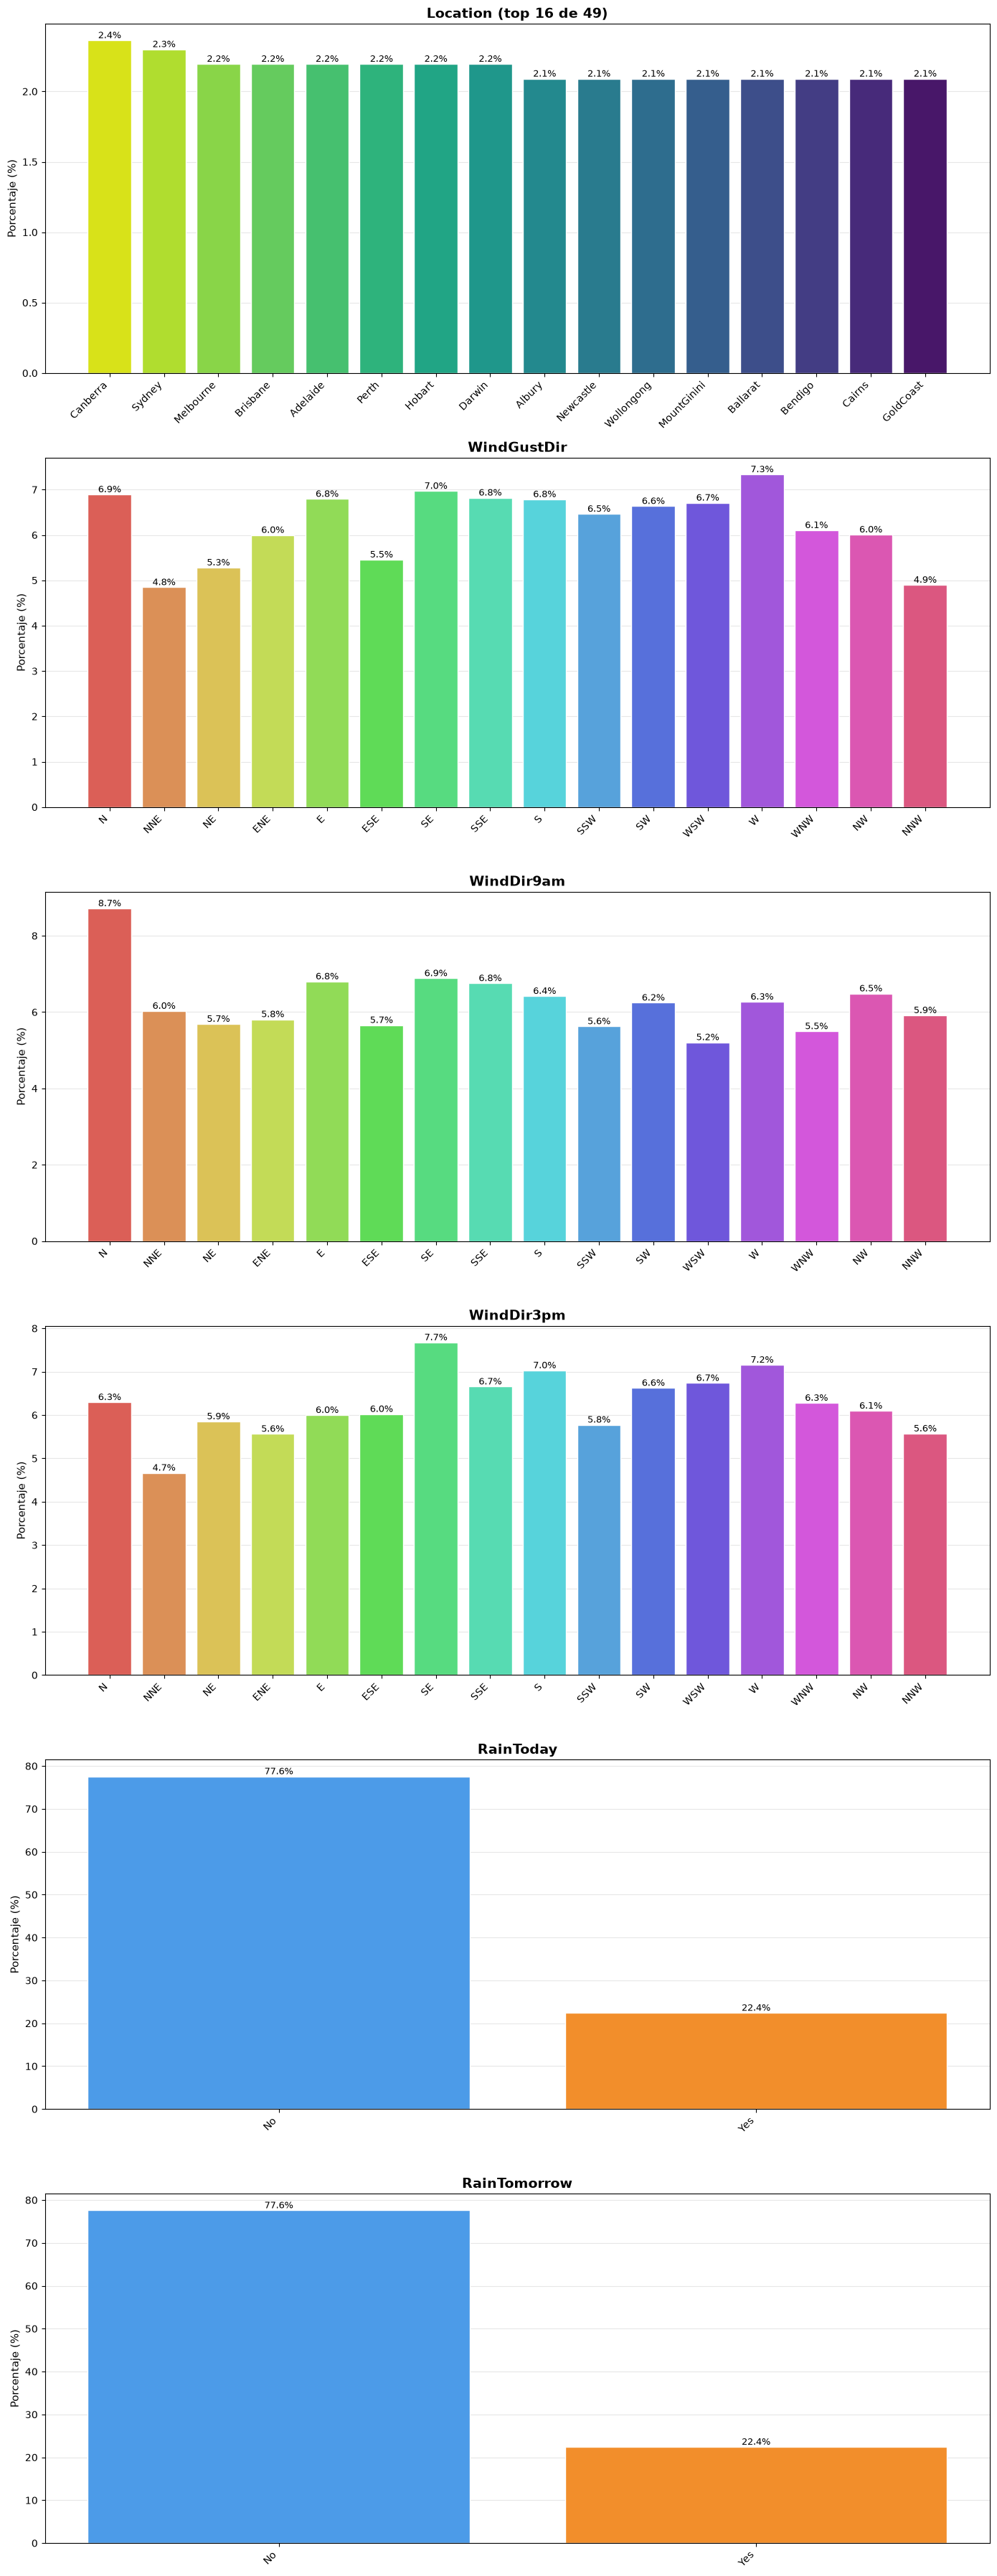

In [ ]:
vars_categoricas = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
vars_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
# Ordenamos los puntos cardinales segun como se encuentran en la brújula, 
# para que los gráficos de barras tengan un orden lógico.
orden_brujula = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
                 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
colores_si_no = {'No': '#4C9BE8', 'Yes': '#F28E2B'}

def graficar_categoricas(df, columnas, top_n=16, porcentaje=True):
    """Gráfico de barras por variable categórica, uno debajo del otro, con colores según el tipo de variable.
    - Viento: orden de brújula y paleta cíclica.
    - Variables Yes/No: azul/naranja.
    - Resto (ej. Location): degradé por frecuencia, limitado a las top_n categorías."""
    fig, axes = plt.subplots(len(columnas), 1, figsize=(14, 6 * len(columnas)))
    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, columnas):
        conteo = df[col].value_counts()
        titulo = col

        if col in vars_viento:
            conteo = conteo.reindex(orden_brujula, fill_value=0)
            colores = sns.color_palette('hls', len(conteo))
        elif set(conteo.index) <= set(colores_si_no):
            conteo = conteo.reindex(['No', 'Yes'], fill_value=0)
            colores = [colores_si_no[c] for c in conteo.index]
        else:
            if len(conteo) > top_n:
                titulo = f'{col} (top {top_n} de {len(conteo)})'
                conteo = conteo.head(top_n)
            colores = sns.color_palette('viridis_r', len(conteo))

        valores = conteo / df[col].notna().sum() * 100 if porcentaje else conteo
        barras = ax.bar(valores.index.astype(str), valores.values, color=colores, edgecolor='white')

        ax.set_title(titulo, fontsize=14, fontweight='bold')
        ax.set_ylabel('Porcentaje (%)' if porcentaje else 'Frecuencia', fontsize=11)
        ax.tick_params(axis='x', rotation=45, labelsize=10)
        for etiqueta in ax.get_xticklabels():
            etiqueta.set_ha('right')
        ax.grid(axis='y', alpha=0.3)
        ax.set_axisbelow(True)
        for barra in barras:
            texto = f'{barra.get_height():.1f}%' if porcentaje else f'{int(barra.get_height())}'
            ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

graficar_categoricas(df, vars_categoricas)

##### Correlaciones de Pearson y Spearman

##### Matrices de correlacion

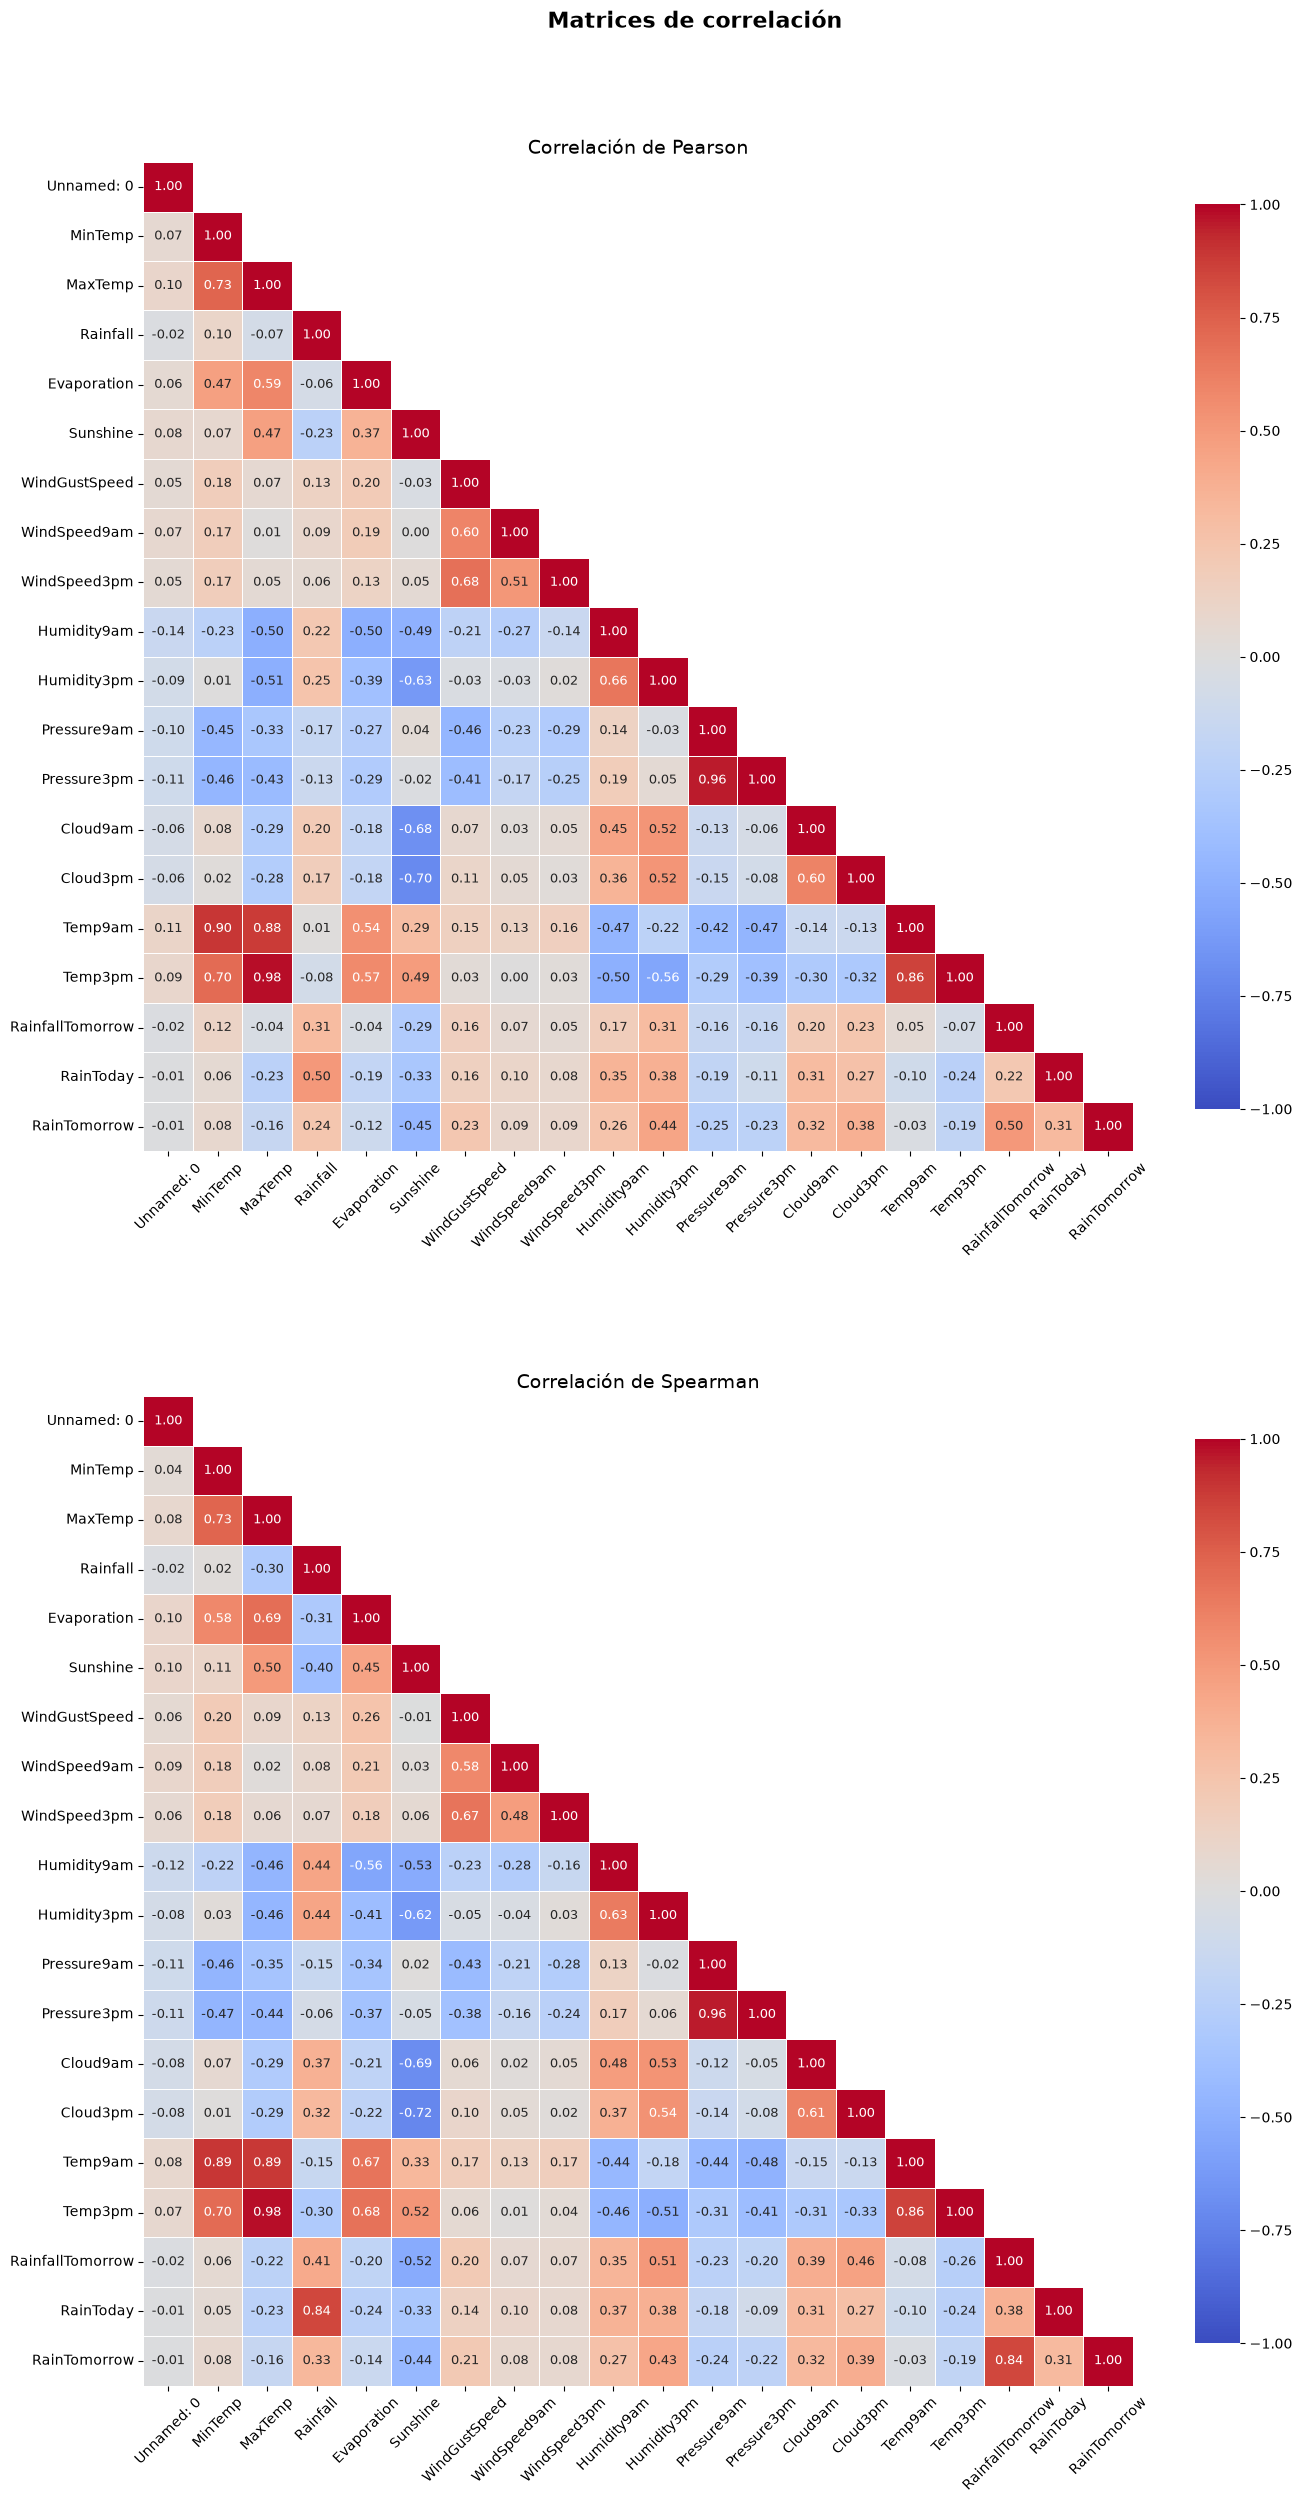

In [44]:
# Variables numéricas del dataset + binarias (Yes/No -> 1/0)
df_num = df.select_dtypes(include='number').copy()
for col in ['RainToday', 'RainTomorrow']:
    df_num[col] = df[col].map({'No': 0, 'Yes': 1})

# ---------- Matrices de correlación: Pearson y Spearman (una debajo de la otra) ----------
fig, axes = plt.subplots(2, 1, figsize=(14, 26))
fig.suptitle('Matrices de correlación', fontsize=16, fontweight='bold')

for ax, metodo in zip(axes, ['pearson', 'spearman']):
    corr = df_num.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)  # oculta el triángulo superior (redundante)
    sns.heatmap(corr, ax=ax, mask=mascara, annot=True, fmt='.2f', annot_kws={'size': 9},
                cmap='coolwarm', vmin=-1, vmax=1, square=True,
                linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax.set_title(f'Correlación de {metodo.capitalize()}', fontsize=14)
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    ax.tick_params(axis='y', rotation=0, labelsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

En base  alo observado, podemos notar que hay variables muy fuertemente correlacionadas (+ del 90%):
- Temp3pm y MaxTemp
- Pressure3pm y Pressure 9am

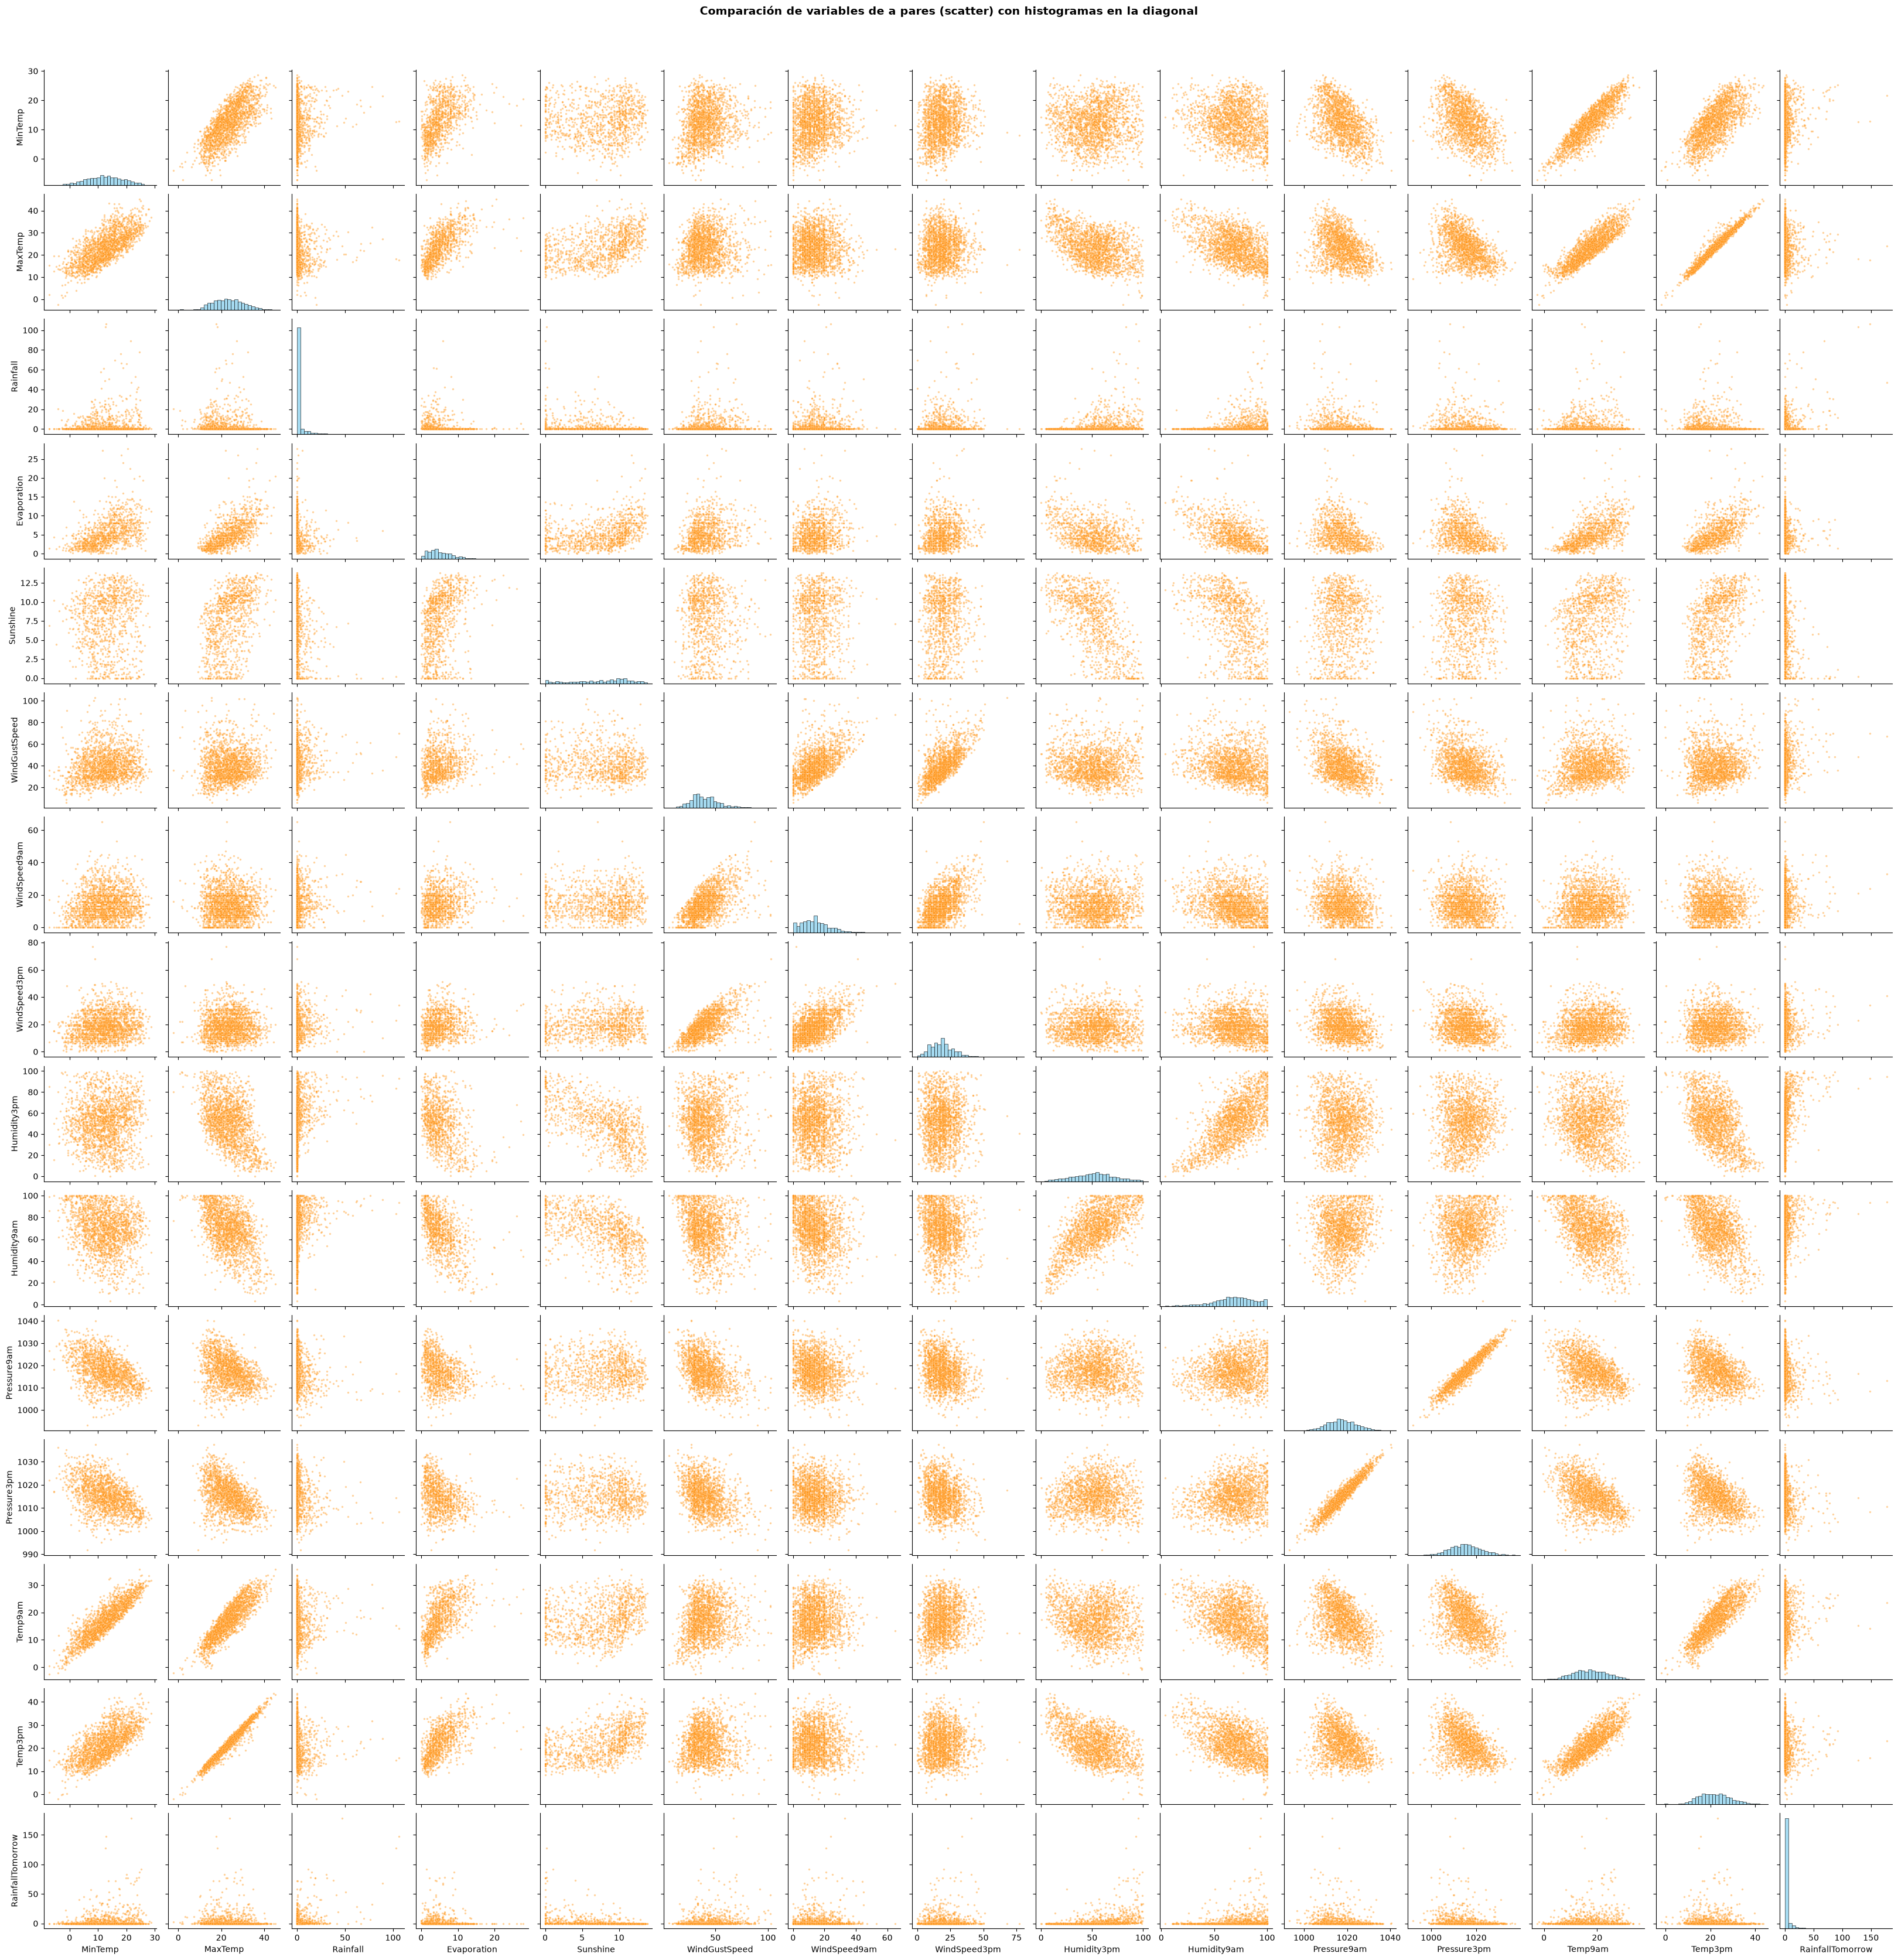

In [50]:
# ---------- Gráfico de pares: scatters + histogramas en la diagonal ----------
# Se excluye Unnamed: 0 (índice), RainToday y RainTomorrow (binarias), Location, WindGustDir, WindDir3pm y WindDir9am (categórica),
# además de Cloud9am y Cloud3pm que son numericas discretas y no aportan información relevante para este gráfico.
variables_numericas_continuas = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                                 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity3pm', 
                                 'Humidity9am', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm', 'RainfallTomorrow']

# Se usa una muestra para que el gráfico no tarde demasiado
muestra = df_num[variables_numericas_continuas].sample(n=min(2000, len(df_num)), random_state=42)

g = sns.pairplot(muestra, diag_kind='hist',
                 plot_kws={'s': 6, 'alpha': 0.4, 'color': 'darkorange'},
                 diag_kws={'color': 'skyblue', 'edgecolor': 'black', 'bins': 30},
                 height=2.2)
g.fig.suptitle('Comparación de variables de a pares (scatter) con histogramas en la diagonal',
               y=1.02, fontsize=14, fontweight='bold')
plt.show()


### Limpieza

##### 1. Unnamed: 0

La primer columna, 'Unnamed: 0', representa el índice del dataset. Pero al examinarla detalladamente notamos que hay valores erroneos dentro de ella (no consecutivos, salteo, etc).
Existen 2 opciones: eliminarla y crearla nuevamente para que se respete el orden de las filas; o bien eliminarla definitivamente. SAeguiremos esta segunda opcion, ya que para el analisis posterior no será necesaria esta información.

In [ ]:
df.drop(columns="Unnamed: 0", inplace=True)

df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
